# Who runs short-term rentals in Paris?

Data: Inside Airbnb snapshot of Paris, 16 September 2026 (CC BY 4.0).

Three questions:
1. How much of the active entire-home supply belongs to hosts with several homes?
2. Does that differ by arrondissement, and do those listings behave differently?
3. How usable is the registration number field for spotting problem listings?

In [1]:
import json, os, re, warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize

pd.set_option("display.width", 160, "display.max_columns", 30)

DATA = Path(os.environ.get("PARIS_DATA_DIR", "../data/raw"))
FIG = Path("../figures")
FIG.mkdir(exist_ok=True)

INK, MUTED, GRID, ACCENT = "#22262b", "#6b7280", "#e5e7eb", "#1f5fae"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 170, "savefig.bbox": "tight",
    "font.size": 10, "text.color": INK, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": INK, "axes.edgecolor": GRID,
    "axes.spines.top": False, "axes.spines.right": False,
})

ARR = {"Louvre": 1, "Bourse": 2, "Temple": 3, "Hôtel-de-Ville": 4, "Panthéon": 5,
       "Luxembourg": 6, "Palais-Bourbon": 7, "Élysée": 8, "Opéra": 9, "Entrepôt": 10,
       "Popincourt": 11, "Reuilly": 12, "Gobelins": 13, "Observatoire": 14,
       "Vaugirard": 15, "Passy": 16, "Batignolles-Monceau": 17, "Buttes-Montmartre": 18,
       "Buttes-Chaumont": 19, "Ménilmontant": 20}

raw = pd.read_csv(DATA / "listings.csv.gz", low_memory=False)
raw.shape

(77149, 90)

## 1. Scope

A listing with no guests is not supply, and a 30+ night minimum is not short-term rental. So I keep entire homes with a minimum stay under 30 nights and at least one review in the last 12 months. Reviews are an imperfect sign of activity: a real listing can go a year without one.

In [2]:
is_entire = raw.room_type.eq("Entire home/apt")
is_short = raw.minimum_nights.lt(30)
is_active = raw.number_of_reviews_ltm.gt(0)

funnel = pd.Series({
    "All listings": len(raw),
    "Entire homes": is_entire.sum(),
    "... with minimum stay under 30 nights": (is_entire & is_short).sum(),
    "... and a review in the last 12 months": (is_entire & is_short & is_active).sum(),
}, name="listings")

df = raw[is_entire & is_short & is_active].copy()
df["arr"] = df.neighbourhood_cleansed.map(ARR)
df["homes"] = df.calculated_host_listings_count_entire_homes
funnel.to_frame()

,listings
All listings,77149
Entire homes,68333
... with minimum stay under 30 nights,53472
... and a review in the last 12 months,32473


## 2. How much supply sits with multi-home hosts?

There is no field for "professional", so the threshold is my choice. I use 3 or more entire homes in the headline and show how the answer moves with other cut-offs.

In [3]:
PRO_MIN = 3
df["multi"] = df.homes.ge(PRO_MIN)

sens = pd.DataFrame({
    "min_homes": [2, 3, 5, 10],
    "share_of_listings": [df.homes.ge(k).mean() for k in [2, 3, 5, 10]],
    "hosts": [df.loc[df.homes.ge(k), "host_id"].nunique() for k in [2, 3, 5, 10]],
})

by_host = df.groupby("host_id").size().sort_values(ascending=False)
top1 = by_host.head(max(1, int(len(by_host) * 0.01)))
print(f"Hosts in scope: {len(by_host):,}")
print(f"Top 1% of hosts ({len(top1)}) hold {top1.sum() / by_host.sum():.1%} of listings")
sens.style.format({"share_of_listings": "{:.1%}", "hosts": "{:,}"})

Hosts in scope: 22,829
Top 1% of hosts (228) hold 19.4% of listings


,min_homes,share_of_listings,hosts
0,2,37.2%,"2,432"
1,3,31.5%,"1,214"
2,5,27.3%,712
3,10,21.8%,347


## 3. By arrondissement

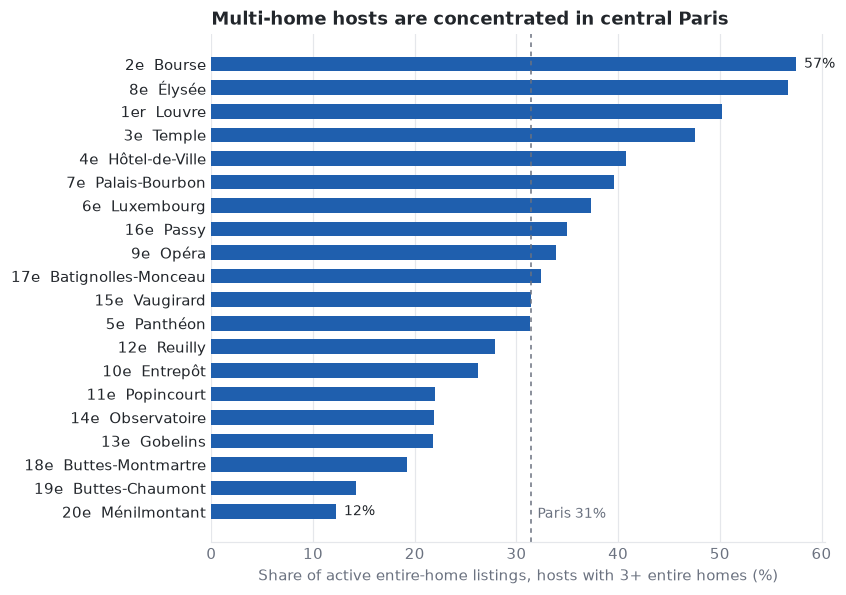

label,listings,multi_share,median_nights
2e Bourse,1677,57.5%,114.000000
8e Élysée,1165,56.7%,104.000000
1er Louvre,998,50.2%,104.000000
3e Temple,1953,47.6%,104.000000
4e Hôtel-de-Ville,1300,40.8%,104.000000
7e Palais-Bourbon,944,39.6%,94.000000
6e Luxembourg,1060,37.4%,94.000000
16e Passy,1646,35.0%,83.000000
9e Opéra,1537,33.9%,104.000000
17e Batignolles-Monceau,1717,32.4%,94.000000


In [4]:
arr = (df.groupby(["arr", "neighbourhood_cleansed"])
         .agg(listings=("id", "size"), multi_share=("multi", "mean"),
              median_nights=("estimated_occupancy_l365d", "median"))
         .reset_index().sort_values("multi_share"))
arr["label"] = arr.arr.map(lambda n: "1er" if n == 1 else f"{n}e") + "  " + arr.neighbourhood_cleansed

fig, ax = plt.subplots(figsize=(7.2, 6))
ax.barh(arr.label, arr.multi_share * 100, color=ACCENT, height=0.62)
overall = df.multi.mean() * 100
ax.axvline(overall, color=MUTED, lw=1, ls=(0, (3, 3)))
ax.text(overall + 0.6, -0.1, f"Paris {overall:.0f}%", color=MUTED, fontsize=9, va="center")
for y, v in enumerate(arr.multi_share * 100):
    if y in (0, len(arr) - 1):
        ax.text(v + 0.8, y, f"{v:.0f}%", va="center", fontsize=9)
ax.set_xlabel("Share of active entire-home listings, hosts with 3+ entire homes (%)")
ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.tick_params(length=0); ax.spines["left"].set_visible(False)
ax.set_title("Multi-home hosts are concentrated in central Paris", loc="left", fontweight="bold")
fig.savefig(FIG / "multi_home_share_by_arrondissement.png")
plt.show()
arr[["label", "listings", "multi_share", "median_nights"]].sort_values("multi_share", ascending=False).style.format({"multi_share": "{:.1%}"}).hide(axis="index")

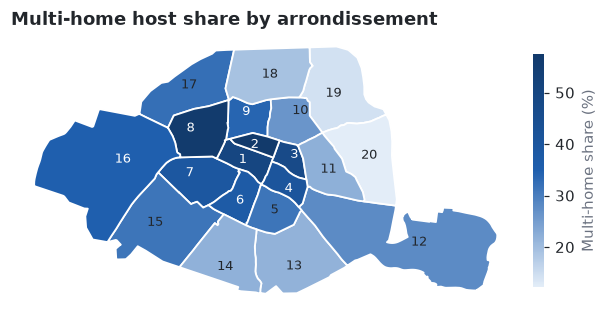

In [5]:
geo = json.loads((DATA / "neighbourhoods.geojson").read_text(encoding="utf-8"))
values = arr.set_index("neighbourhood_cleansed").multi_share * 100
cmap = LinearSegmentedColormap.from_list("blue", ["#e3edf8", ACCENT, "#123a6b"])
norm = Normalize(values.min(), values.max())

polys, colors, centers = [], [], []
for feature in geo["features"]:
    name = feature["properties"]["neighbourhood"]
    geometry = feature["geometry"]
    parts = geometry["coordinates"] if geometry["type"] == "MultiPolygon" else [geometry["coordinates"]]
    biggest = max(parts, key=lambda p: len(p[0]))
    for part in parts:
        polys.append(np.array(part[0])); colors.append(cmap(norm(values[name])))
    centers.append((name, np.array(biggest[0]).mean(axis=0)))

fig, ax = plt.subplots(figsize=(7.2, 5))
ax.add_collection(PolyCollection(polys, facecolors=colors, edgecolors="white", linewidths=1.2))
for name, (x, y) in centers:
    share = values[name]
    ax.text(x, y, ARR[name], ha="center", va="center", fontsize=8.5,
            color="white" if norm(share) > 0.45 else INK)
ax.autoscale_view(); ax.set_aspect(1 / np.cos(np.radians(48.86))); ax.axis("off")
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
bar = fig.colorbar(sm, ax=ax, shrink=0.55, pad=0.02)
bar.set_label("Multi-home share (%)"); bar.outline.set_visible(False)
ax.set_title("Multi-home host share by arrondissement", loc="left", fontweight="bold")
fig.savefig(FIG / "multi_home_share_map.png")
plt.show()

## 4. Do multi-home listings behave differently?

`estimated_occupancy_l365d` is Inside Airbnb's model of nights booked, based on reviews. It is capped at 255 and should be read as a rough estimate. Multi-home hosts are more common in the centre, where demand is high, so I also compare the two groups inside each arrondissement.

In [6]:
compare = df.groupby("multi").agg(
    listings=("id", "size"),
    median_estimated_nights=("estimated_occupancy_l365d", "median"),
    median_nights_open_next_365=("availability_365", "median"),
    mean_rating=("review_scores_rating", "mean"),
    median_estimated_revenue=("estimated_revenue_l365d", "median"),
).rename(index={False: "1-2 entire homes", True: "3+ entire homes"})

within = (df.groupby(["arr", "multi"]).estimated_occupancy_l365d.median().unstack())
within["gap"] = within[True] - within[False]
print(f"Arrondissements where 3+ home hosts have higher median nights: {(within.gap > 0).sum()} of {len(within)}")
print(f"Median gap across arrondissements: {within.gap.median():.0f} nights")
print(f"Revenue is missing for {df.estimated_revenue_l365d.isna().mean():.1%} of listings because price is missing, and is in the source's own currency")
compare.round(2)

Arrondissements where 3+ home hosts have higher median nights: 20 of 20
Median gap across arrondissements: 44 nights
Revenue is missing for 25.3% of listings because price is missing, and is in the source's own currency


,listings,median_estimated_nights,median_nights_open_next_365,mean_rating,median_estimated_revenue
multi,,,,,
1-2 entire homes,22255,83.0,82.0,4.82,19606.5
3+ entire homes,10218,135.0,276.0,4.66,44227.5


## 5. The registration number field

Paris requires a registration number on short-term listings. A valid-looking number proves little: nothing here can check it against the city's register. But the field can still show where it has obviously been filled in badly. Parisian numbers have 13 digits and start with 75.

In [7]:
def classify(value):
    if pd.isna(value):
        return "Missing"
    text = str(value).strip()
    low = text.lower()
    if low.startswith("available with"):
        return "Mobility lease only"
    if low.startswith("exempt"):
        return "Exempt (hotel)"
    if re.fullmatch(r"\d{13}", text) and re.search(r"12345678|3456123|0000000", text):
        return "Placeholder pattern"
    if re.fullmatch(r"75\d{11}", text):
        return "Paris format"
    return "Other format"

df["license_type"] = df.license.map(classify)
types = df.license_type.value_counts().to_frame("listings")
types["share"] = types.listings / len(df)

fmt = df[df.license_type.eq("Paris format")]
hosts_per_number = fmt.groupby("license").host_id.nunique()
listings_per_number = fmt.groupby("license").size()
shared = hosts_per_number[hosts_per_number > 1].index

print(f"Numbers used on more than one listing: {(listings_per_number > 1).sum():,}")
print(f"Numbers used by more than one host account: {len(shared):,}")
print(f"Listings carrying a number shared across hosts: {fmt.license.isin(shared).sum():,}")
types.style.format({"listings": "{:,}", "share": "{:.1%}"})

Numbers used on more than one listing: 557
Numbers used by more than one host account: 215
Listings carrying a number shared across hosts: 495


,listings,share
license_type,,
Paris format,"30,554",94.1%
Exempt (hotel),979,3.0%
Missing,755,2.3%
Other format,105,0.3%
Placeholder pattern,79,0.2%
Mobility lease only,1,0.0%


## 6. Nights above the annual ceiling

Sources I found put the Paris limit for renting out a primary residence at 90 nights a year since 2025. The national default is 120. Some legal commentary still cites 120, so I show both.

The limit only applies to primary residences and the data does not say which listings those are. Hosts with one entire home are the closest proxy, and it is an imperfect one. **This is not evidence of breaches.** It is a way to size how many listings a city inspector might want to look at first.

In [8]:
single = df[df.homes.eq(1)]
rows = []
for limit in (90, 120):
    rows.append({"limit": limit,
                 "single_home_listings_above": single.estimated_occupancy_l365d.gt(limit).sum(),
                 "share_of_single_home": single.estimated_occupancy_l365d.gt(limit).mean()})
pd.DataFrame(rows).style.format({"share_of_single_home": "{:.1%}", "single_home_listings_above": "{:,}"}).hide(axis="index")

limit,single_home_listings_above,share_of_single_home
90,"9,395",46.1%
120,"6,708",32.9%
